# KhushiDL - Ham V/s Spam message analyzer 📨 📱

In [15]:
# importing the neccessary modules
import tensorflow as tf
import matplotlib.pyplot as plt

## Data Preparation

In [5]:
SEED = 21
BATCH = 32

# training dataset raw
train_ds_raw = tf.keras.utils.text_dataset_from_directory(
    "data/train",
    validation_split=.2,
    subset="training",
    batch_size=BATCH,
    seed=21
)

Found 1120 files belonging to 2 classes.
Using 896 files for training.


In [6]:
# validation dataset raw
validation_ds_raw = tf.keras.utils.text_dataset_from_directory(
    "data/train",
    validation_split=.2,
    subset="validation",
    batch_size=BATCH,
    seed=SEED
)

Found 1120 files belonging to 2 classes.
Using 224 files for validation.


In [7]:
# testing dataset raw
test_ds_raw = tf.keras.utils.text_dataset_from_directory(
    "data/test",
    batch_size=BATCH
)

Found 374 files belonging to 2 classes.


### Data Pipeline ⛲️

In [8]:
# creating the datapipeline

AUTOTUNE = tf.data.AUTOTUNE #autotune

train_ds = (
    train_ds_raw
    .cache()
    .prefetch(AUTOTUNE)
    .shuffle(buffer_size=1000)
)

validation_ds = (
    validation_ds_raw
    .cache()
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds_raw
    .cache()
    .prefetch(AUTOTUNE)
)

## TextVectorization

In [9]:
# creating the text vectorization layer

MAX_TOKENS = 5000 # defining the max tokens
SEQUENCE_LENGTH = 200 # defining the max sequence length of the message (prompt)

text_vector = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode='int',
    output_sequence_length=SEQUENCE_LENGTH
)

In [10]:
# adapting the text vectorization

train_text = train_ds.map(lambda text, label: text)
text_vector.adapt(train_text)

## The Model 🧠

In [11]:
# creating the actual model

model = tf.keras.Sequential([
    text_vector,
    tf.keras.layers.Embedding(
        MAX_TOKENS + 1,
        64,
        mask_zero=True
    ),
    tf.keras.layers.Dropout(.4),
    tf.keras.layers.Conv1D(64,5, strides=2,activation='relu'),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.summary() # model summary

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ ?                      │   0 (unbuilt) │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Compiling and Training the model

In [12]:
# compiling the model

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [13]:
# training the model

model_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=15
)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'conv1d' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.4721 - loss: 0.6940 - val_accuracy: 0.4777 - val_loss: 0.6920
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6016 - loss: 0.6871 - val_accuracy: 0.6652 - val_loss: 0.6796
Epoch 3/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8705 - loss: 0.6475 - val_accuracy: 0.8348 - val_loss: 0.6165
Epoch 4/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9029 - loss: 0.5180 - val_accuracy: 0.9152 - val_loss: 0.4585
Epoch 5/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9319 - loss: 0.3350 - val_accuracy: 0.9152 - val_loss: 0.3091
Epoch 6/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9330 - loss: 0.2310 - val_accuracy: 0.9241 - val_loss: 0.2473
Epoch 7/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9464 - loss: 0.1795 - val_accuracy: 0.9241 - val_loss: 0.2111
Epoch 8/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9554 - loss: 0.1466 - val_accuracy: 0.9330 - val_loss: 0.

In [49]:
# testing the model
model.evaluate(test_ds)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9599 - loss: 0.1398


[0.13984107971191406, 0.9598930478096008]

## Graphs 📊

In [16]:
history = model_history.history

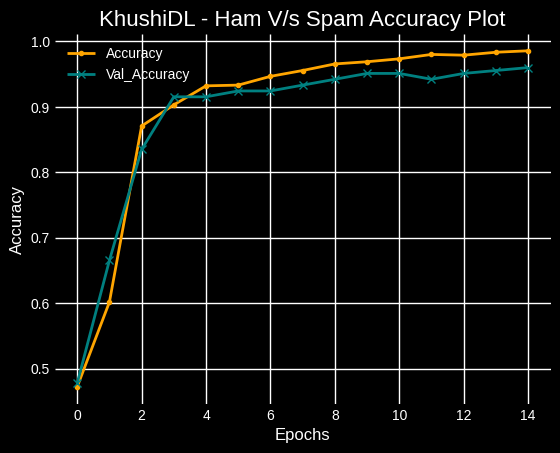

In [58]:
# plotting the accuracy graph
plt.style.use('dark_background')
plt.title("KhushiDL - Ham V/s Spam Accuracy Plot")
plt.plot(history['accuracy'], color='orange', label='Accuracy', marker='.')
plt.plot(history['val_accuracy'], color='teal', label='Val_Accuracy', marker='x')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.savefig("accuracy.png")

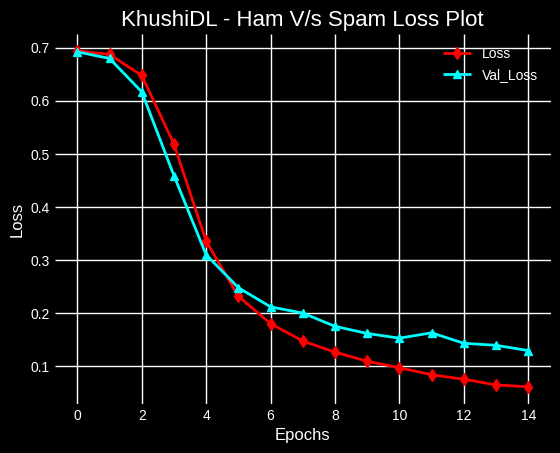

In [59]:
# plotting the loss graph
plt.style.use('dark_background')
plt.title("KhushiDL - Ham V/s Spam Loss Plot")
plt.plot(history['loss'], color='red', label='Loss', marker='d')
plt.plot(history['val_loss'], color='cyan', label='Val_Loss', marker='^')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.savefig("loss.png")

## Testing & Model Info

In [93]:
text="can we go on a date?"
# text = "WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only."

text=tf.constant([text])
prediction = model.predict(text)
if prediction[0][0] >= .5:
  print("It's a spam message with {}% confidence".format((round(prediction[0][0],2))*100))
else:
  print("It's a ham message with {}% confidence".format((1- round(prediction[0][0],2))*100))
print(prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
It's a ham message with 97.0% confidence
0.025949728


In [62]:
for i, label in enumerate(train_ds_raw.class_names):
  print(f"{i} is for {label}")

0 is for ham
1 is for spam


In [94]:
# Exporting the model
model.save("model.keras")